# Kesit İstatistik — İleri nedensel çıkarım ve deney

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Eğilim skoru, eşleştirme ve IPW

Tedavi seçimiyle müdahale etkisini nasıl ayırırım?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Ham farkı IPW ve bilinen simülasyon etkisiyle karşılaştır.

**Yorum sınırı:** IPW gözlenen karıştırıcılar, doğru eğilim modeli, tutarlılık ve pozitiflik ister; gizli karıştırıcıyı çözmez.

**Alıştırma:** Seçilim katsayısını 1’den 2’ye çıkar; uç ağırlık ve ESS’yi incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'ham_fark': np.float64(4.148999357550378), 'Hajek_IPW': np.float64(1.887815662792634), 'gercek_etki': 2, 'tedavi_ESS': np.float64(459.1316205973227), 'kontrol_ESS': np.float64(355.232109176364)}


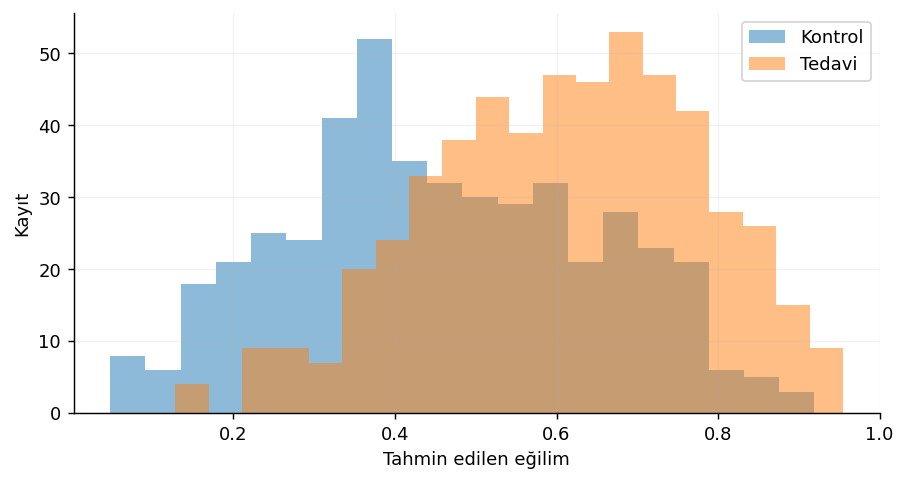

In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.normal(size=1000);prop=special.expit(x);t=rng.binomial(1,prop);y=2*t+3*x+rng.normal(size=1000);m=LogisticRegression(C=1e5).fit(x[:,None],t);e=m.predict_proba(x[:,None])[:,1]
if np.min(e)<.01 or np.max(e)>.99:print('UYARI: zayıf destek / uç ağırlık')
w1=t/e;w0=(1-t)/(1-e);effect=np.sum(w1*y)/w1.sum()-np.sum(w0*y)/w0.sum();ess=lambda w:w.sum()**2/(w@w)
print({'ham_fark':y[t==1].mean()-y[t==0].mean(),'Hajek_IPW':effect,'gercek_etki':2,'tedavi_ESS':ess(w1),'kontrol_ESS':ess(w0)})
plt.hist(e[t==0],bins=20,alpha=.5,label='Kontrol');plt.hist(e[t==1],bins=20,alpha=.5,label='Tedavi');plt.xlabel('Tahmin edilen eğilim');plt.ylabel('Kayıt');plt.legend()

## Araç değişken ve doğal deney

Dışsal araç endojenlik sorununu nasıl değiştirebilir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** OLS, 2SLS ve bilinen üretim etkisini karşılaştır.

**Yorum sınırı:** Araç dışsallığı ve dışlama veriyle tek başına kanıtlanmaz; ikinci aşama saf OLS standart hatası geçerli değildir.

**Alıştırma:** Araç katsayısını 1’den .1’e indir; ilk aşama F ve tahmini incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'OLS': np.float64(2.310819632947627), '2SLS_nokta': np.float64(2.0463583425656537), 'gercek': 2, 'ilk_asama_F': 744.3460653854601, 'CI': 'Bu örnekte IV güven aralığı hesaplanmadı'}


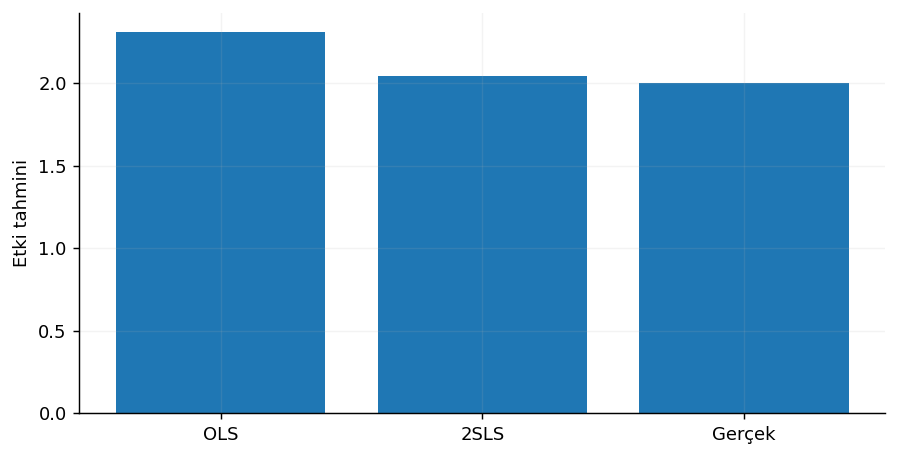

In [114]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

n=1200;z=rng.normal(size=n);u=rng.normal(size=n);t=z+.8*u+rng.normal(size=n);y=2*t+u+rng.normal(size=n);first=sm.OLS(t,sm.add_constant(z)).fit();that=first.fittedvalues;beta_iv=sm.OLS(y,sm.add_constant(that)).fit().params[1];ols=sm.OLS(y,sm.add_constant(t)).fit().params[1]
print({'OLS':ols,'2SLS_nokta':beta_iv,'gercek':2,'ilk_asama_F':float(first.fvalue),'CI':'Bu örnekte IV güven aralığı hesaplanmadı'})
plt.bar(['OLS','2SLS','Gerçek'],[ols,beta_iv,2]);plt.ylabel('Etki tahmini')

## Regresyon süreksizliği

Bir eşik çevresinde yerel etkiyi nasıl kurarım?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** İki taraftaki yerel doğruların eşikteki sıçramasını oku.

**Yorum sınırı:** Süreklilik, manipülasyon olmaması ve uygun bant gerekir; etki eşik çevresine aittir.

**Alıştırma:** Bant genişliğini .6’dan .3’e indir; n ve aralığın değişimini karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'yerel_n': 237, 'sicrama': np.float64(1.8505145267244167), 'HC1_CI': [1.3761987951340424, 2.324830258314791], 'gercek': 1.5}


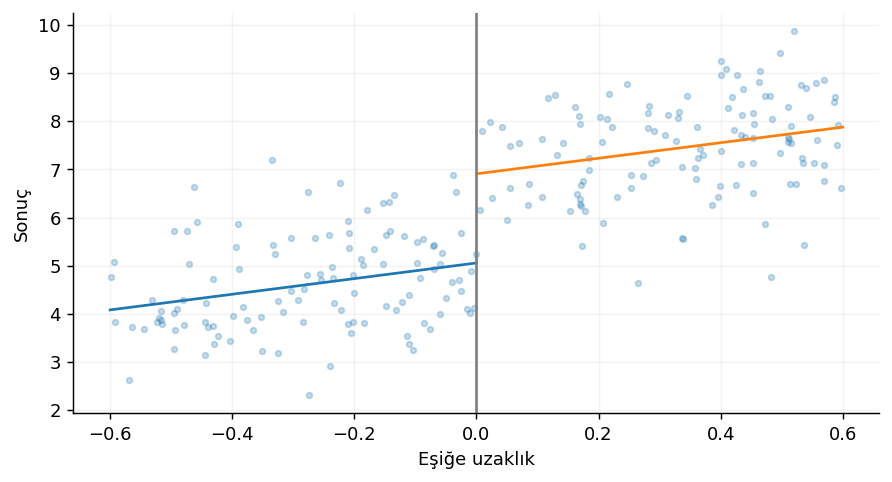

In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.uniform(-2,2,800);t=(x>=0).astype(int);y=5+2*x+1.5*t+.4*x*t+rng.normal(size=len(x));band=.6;keep=np.abs(x)<=band;df=pd.DataFrame({'x':x[keep],'t':t[keep],'y':y[keep]});fit=smf.ols('y ~ x * t',df).fit(cov_type='HC1');print({'yerel_n':int(keep.sum()),'sicrama':fit.params['t'],'HC1_CI':fit.conf_int().loc['t'].tolist(),'gercek':1.5})
plt.scatter(df.x,df.y,s=10,alpha=.25)
for g in [0,1]:
 grid=np.linspace(-band,0,60) if g==0 else np.linspace(0,band,60);plt.plot(grid,fit.predict(pd.DataFrame({'x':grid,'t':g})))
plt.axvline(0,c='gray');plt.xlabel('Eşiğe uzaklık');plt.ylabel('Sonuç')

## Sıralı deneyler ve varyans azaltma

Tekrarlı bakış ve ön dönem bilgisi deneyi nasıl etkiler?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Önceden planlı dört bakışı Bonferroni eşiğiyle oku; CUPED varyansını ayrı karşılaştır.

**Yorum sınırı:** Bu basit dört bakış düzeltmesi always-valid veya genel grup sıralı tasarım değildir. CUPED kovaryatı tedavi öncesi olmalı.

**Alıştırma:** Etkiyi .15’ten 0’a indir; tek simülasyondan tip I hata oranı çıkarmamaya dikkat et.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'bakis_p': [np.float64(0.06447387608549475), np.float64(0.0010567565716126737), np.float64(0.023325880684379748), np.float64(0.014167369198746234)], 'planli_esik': 0.0125, 'ham_varyans': np.float64(1.6273526233518292), 'CUPED_varyans': np.float64(1.0114659402379582), 'theta': np.float64(0.8008737990489679)}


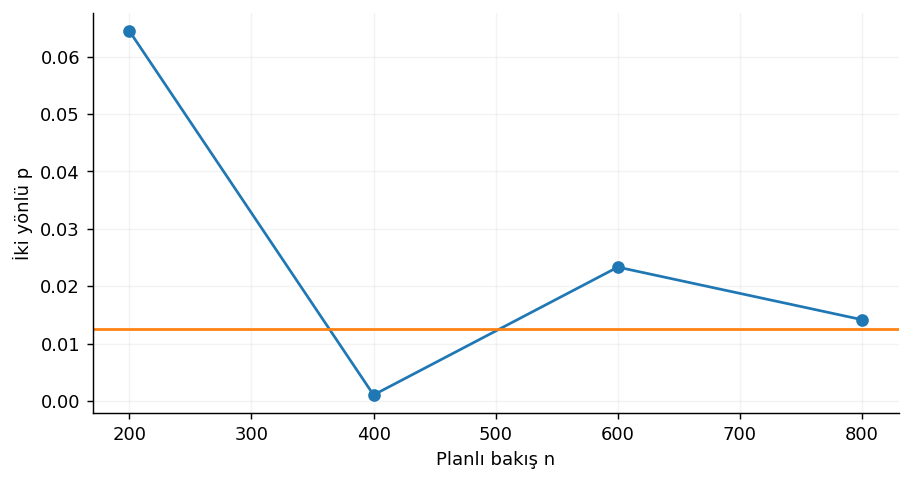

In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

n=800;pre=rng.normal(size=n);t=rng.binomial(1,.5,n);y=.15*t+.8*pre+rng.normal(size=n);theta=np.cov(y,pre,ddof=1)[0,1]/np.var(pre,ddof=1);adjusted=y-theta*(pre-pre.mean());looks=[200,400,600,800];p=[]
for k in looks:p.append(stats.ttest_ind(y[:k][t[:k]==1],y[:k][t[:k]==0],equal_var=False).pvalue)
print({'bakis_p':p,'planli_esik':.05/len(looks),'ham_varyans':np.var(y),'CUPED_varyans':np.var(adjusted),'theta':theta});plt.plot(looks,p,'o-');plt.axhline(.05/len(looks),c='tab:orange');plt.xlabel('Planlı bakış n');plt.ylabel('İki yönlü p')